In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

# Notebook'u ister kök dizinden ister notebooks/ içinden çalıştır, yolu otomatik bulur
raw_dir = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
csv_files = list(raw_dir.glob("*.csv"))
assert len(csv_files) > 0, f"{raw_dir.resolve()} içinde CSV bulunamadı!"

data_path = csv_files[0]
print(f"Yüklenen dosya: {data_path.name}")

df = pd.read_csv(data_path, low_memory=False)
mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Satır sayısı : {df.shape[0]:,}")
print(f"Sütun sayısı : {df.shape[1]}")
print(f"RAM kullanımı: {mem_mb:.2f} MB")
df.head(3)

Yüklenen dosya: ML-EdgeIIoT-dataset.csv
Satır sayısı : 157,800
Sütun sayısı : 63
RAM kullanımı: 123.08 MB


,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,icmp.unused,http.file_data,http.content_length,http.request.uri.query,http.request.method,http.referer,http.request.full_uri,http.request.version,http.response,http.tls_port,tcp.ack,tcp.ack_raw,tcp.checksum,tcp.connection.fin,tcp.connection.rst,tcp.connection.syn,tcp.connection.synack,tcp.dstport,tcp.flags,tcp.flags.ack,tcp.len,tcp.options,tcp.payload,tcp.seq,tcp.srcport,udp.port,udp.stream,udp.time_delta,dns.qry.name,dns.qry.name.len,dns.qry.qu,dns.qry.type,dns.retransmission,dns.retransmit_request,dns.retransmit_request_in,mqtt.conack.flags,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msg_decoded_as,mqtt.msg,mqtt.msgtype,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


In [2]:
summary = []
for col in df.columns:
    s = df[col]
    n_missing = int(s.isna().sum())
    n_unique = int(s.nunique(dropna=True))
    zero_pct = s.isin([0, 0.0, "0", "0.0"]).mean() * 100
    samples = s.dropna().unique()[:3].tolist()
    summary.append({
        "column": col,
        "dtype": str(s.dtype),
        "missing": n_missing,
        "nunique": n_unique,
        "zero_pct": round(zero_pct, 2),
        "sample_values": str(samples)[:60]
    })

eda_df = pd.DataFrame(summary)

print("=== SIFIR VARYANSLI (TEK DEĞERLİ) SÜTUNLAR ===")
const_cols = eda_df[eda_df["nunique"] <= 1]["column"].tolist()
print(const_cols if const_cols else "Yok")

print("\n=== EKSİK (NaN) DEĞER İÇEREN SÜTUNLAR ===")
missing_cols = eda_df[eda_df["missing"] > 0][["column", "missing"]]
print(missing_cols if len(missing_cols) > 0 else "Eksik değer yok")

print("\n=== METİN (OBJECT) TİPİNDEKİ SÜTUNLAR ===")
print(eda_df[eda_df["dtype"] == "object"][["column", "nunique", "sample_values"]].to_string(index=False))

eda_df

=== SIFIR VARYANSLI (TEK DEĞERLİ) SÜTUNLAR ===
['icmp.unused', 'http.tls_port', 'dns.qry.type', 'dns.retransmit_request_in', 'mqtt.msg_decoded_as', 'mbtcp.len', 'mbtcp.trans_id', 'mbtcp.unit_id']

=== EKSİK (NaN) DEĞER İÇEREN SÜTUNLAR ===
Eksik değer yok

=== METİN (OBJECT) TİPİNDEKİ SÜTUNLAR ===
Empty DataFrame
Columns: [column, nunique, sample_values]
Index: []


,column,dtype,missing,nunique,zero_pct,sample_values
0,frame.time,str,0,155186,0.55,"['6.0', '0.0', ' 2021 22:14:30.939803000 ']"
1,ip.src_host,str,0,19090,5.06,"['192.168.0.152', '192.168.0.101', '0']"
2,ip.dst_host,str,0,8084,13.58,"['0.0', '192.168.0.128', '192.168.0.170']"
3,arp.dst.proto_ipv4,str,0,8,98.11,"['0.0', '0', '192.168.0.128']"
4,arp.opcode,float64,0,3,99.00,"[0.0, 1.0, 2.0]"
5,arp.hw.size,float64,0,2,99.00,"[0.0, 6.0]"
6,arp.src.proto_ipv4,str,0,8,99.00,"['0.0', '0', '192.168.0.170']"
7,icmp.checksum,float64,0,13187,90.70,"[0.0, 11938.0, 13986.0]"
8,icmp.seq_le,float64,0,13824,90.08,"[0.0, 256.0, 8154.0]"
9,icmp.transmit_timestamp,float64,0,84,99.95,"[0.0, 76471910.0, 76496315.0]"


In [3]:
# Sayısal sütunlarda sonsuz (inf / -inf) değer kontrolü
num_df = df.select_dtypes(include=[np.number])
inf_counts = np.isinf(num_df).sum()
inf_cols = inf_counts[inf_counts > 0]
print("=== SONSUZ (INF) DEĞER İÇEREN SÜTUNLAR ===")
print(inf_cols if len(inf_cols) > 0 else "Yok")

print("\n=== İKİLİ HEDEF DAĞILIMI (Attack_label) ===")
label_counts = df["Attack_label"].value_counts()
label_pct = df["Attack_label"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Adet": label_counts, "Yüzde (%)": label_pct.round(2)}))

print("\n=== SALDIRI TÜRÜ DAĞILIMI (Attack_type) ===")
type_counts = df["Attack_type"].value_counts()
type_pct = df["Attack_type"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Adet": type_counts, "Yüzde (%)": type_pct.round(2)}))

=== SONSUZ (INF) DEĞER İÇEREN SÜTUNLAR ===
Yok

=== İKİLİ HEDEF DAĞILIMI (Attack_label) ===
                Adet  Yüzde (%)
Attack_label                   
1             133499       84.6
0              24301       15.4

=== SALDIRI TÜRÜ DAĞILIMI (Attack_type) ===
                        Adet  Yüzde (%)
Attack_type                            
Normal                 24301      15.40
DDoS_UDP               14498       9.19
DDoS_ICMP              14090       8.93
Ransomware             10925       6.92
DDoS_HTTP              10561       6.69
SQL_injection          10311       6.53
Uploading              10269       6.51
DDoS_TCP               10247       6.49
Backdoor               10195       6.46
Vulnerability_scanner  10076       6.39
Port_Scanning          10071       6.38
XSS                    10052       6.37
Password                9989       6.33
MITM                    1214       0.77
Fingerprinting          1001       0.63


In [4]:
check_cols = [
    "tcp.srcport", "tcp.dstport", "udp.port",
    "icmp.unused", "http.tls_port", "mqtt.msg_decoded_as"
]

for col in check_cols:
    if col in df.columns:
        print(f"\n--- {col} (dtype={df[col].dtype}, nunique={df[col].nunique()}) ---")
        print(df[col].value_counts(dropna=False).head(8))


--- tcp.srcport (dtype=str, nunique=32186) ---
tcp.srcport
80.0       34437
0.0        19610
1883.0     10075
4321.0      9660
47924.0     3002
5900.0      2844
60210.0     2559
56322.0     2082
Name: count, dtype: int64

--- tcp.dstport (dtype=float64, nunique=23188) ---
tcp.dstport
80.0       41581
0.0        33920
1883.0      9951
4321.0      9890
47924.0     2961
60944.0     2774
60210.0     2502
56322.0     1976
Name: count, dtype: int64

--- udp.port (dtype=float64, nunique=32) ---
udp.port
0.0        157395
22.0          216
21.0           77
15.0           74
53.0            7
123.0           4
5353.0          2
59638.0         1
Name: count, dtype: int64

--- icmp.unused (dtype=float64, nunique=1) ---
icmp.unused
0.0    157800
Name: count, dtype: int64

--- http.tls_port (dtype=float64, nunique=1) ---
http.tls_port
0.0    157800
Name: count, dtype: int64

--- mqtt.msg_decoded_as (dtype=float64, nunique=1) ---
mqtt.msg_decoded_as
0.0    157800
Name: count, dtype: int64


In [5]:
leakage_and_meta_cols = [
    # Zaman ve kimlik sızıntıları
    "frame.time", "ip.src_host", "ip.dst_host",
    "arp.src.proto_ipv4", "arp.dst.proto_ipv4", "icmp.transmit_timestamp",
    # Ham payload ve yüksek kardinaliteli testbed metinleri
    "tcp.payload", "tcp.options", "http.file_data",
    "http.request.full_uri", "http.request.uri.query", "http.referer",
    "dns.qry.name", "mqtt.msg", "mqtt.topic",
    # Rastgele ID, checksum ve akış indeksi
    "icmp.checksum", "tcp.checksum", "tcp.ack_raw", "mbtcp.trans_id", "udp.stream",
    # Hedef sütunlar
    "Attack_label", "Attack_type"
]

candidate_features = [c for c in df.columns if c not in leakage_and_meta_cols]
print(f"Aday davranışsal özellik sayısı: {len(candidate_features)}")

# 1) Ham veri üzerinde birebir kopya satır sayısı
raw_dups = df.duplicated().sum()
print(f"1. Ham verideki tam kopya satır sayısı: {raw_dups:,} (%{raw_dups / len(df) * 100:.2f})")

# 2) Sızıntı sütunları hariç (özellik + Attack_label) kopya satır sayısı
dedup_fl = df.drop_duplicates(subset=candidate_features + ["Attack_label"])
feat_label_dups = len(df) - len(dedup_fl)
print(f"2. Temiz özellik + Attack_label bazında kopya satır: {feat_label_dups:,} (%{feat_label_dups / len(df) * 100:.2f})")
print(f"   -> Kopyalar çıkarılırsa kalan tekil satır: {len(dedup_fl):,}")

# 3) Çelişkili kopyalar (tüm davranışsal özellikler aynı ama biri 0, diğeri 1)
conflict_mask = dedup_fl.duplicated(subset=candidate_features, keep=False)
n_conflict_patterns = conflict_mask.sum() // 2
print(f"3. Çelişkili (hem Normal hem Saldırı etiketi almış) benzersiz özellik örüntüsü: {n_conflict_patterns:,}")

# 4) Kopyalar çıkarıldığında Attack_type dağılımı nasıl değişiyor?
print("\n=== DEDUPLICATION ÖNCESİ vs SONRASI (Attack_type) ===")
compare_df = pd.DataFrame({
    "Öncesi": df["Attack_type"].value_counts(),
    "Sonrası": dedup_fl["Attack_type"].value_counts()
}).fillna(0).astype(int)
compare_df["Kalan (%)"] = (compare_df["Sonrası"] / compare_df["Öncesi"] * 100).round(1)
print(compare_df)

Aday davranışsal özellik sayısı: 41
1. Ham verideki tam kopya satır sayısı: 814 (%0.52)
2. Temiz özellik + Attack_label bazında kopya satır: 12,133 (%7.69)
   -> Kopyalar çıkarılırsa kalan tekil satır: 145,667
3. Çelişkili (hem Normal hem Saldırı etiketi almış) benzersiz özellik örüntüsü: 0

=== DEDUPLICATION ÖNCESİ vs SONRASI (Attack_type) ===
                       Öncesi  Sonrası  Kalan (%)
Attack_type                                      
Backdoor                10195     9847       96.6
DDoS_HTTP               10561     9734       92.2
DDoS_ICMP               14090    12434       88.2
DDoS_TCP                10247    10099       98.6
DDoS_UDP                14498    13285       91.6
Fingerprinting           1001      274       27.4
MITM                     1214      358       29.5
Normal                  24301    23134       95.2
Password                 9989     9451       94.6
Port_Scanning           10071     8918       88.6
Ransomware              10925     9531       87.2
SQL

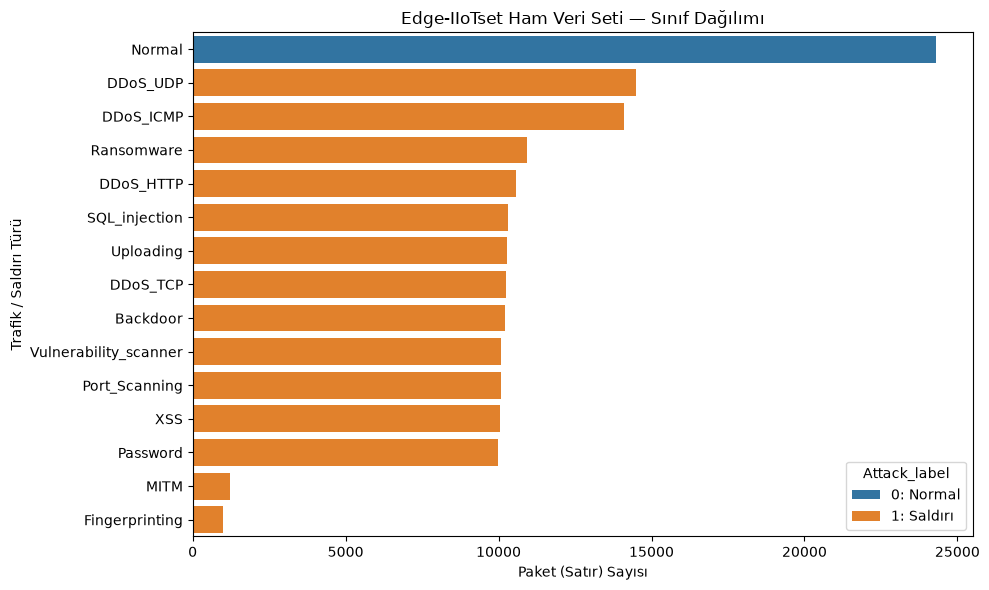

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
order = df["Attack_type"].value_counts().index
sns.countplot(data=df, y="Attack_type", order=order, hue="Attack_label", dodge=False)
plt.title("Edge-IIoTset Ham Veri Seti — Sınıf Dağılımı")
plt.xlabel("Paket (Satır) Sayısı")
plt.ylabel("Trafik / Saldırı Türü")
plt.legend(title="Attack_label", labels=["0: Normal", "1: Saldırı"])
plt.tight_layout()
plt.show()

In [7]:
# 1) tcp.srcport içinde sayıya çevrilemeyen (kaymış) satır sayısı ve dağılımı
srcport_num = pd.to_numeric(df["tcp.srcport"], errors="coerce")
bad_srcport = srcport_num.isna()
print(f"1. tcp.srcport'ta sayısal olmayan (kaymış) satır sayısı: {bad_srcport.sum():,}")
if bad_srcport.sum() > 0:
    print("   Attack_type dağılımı:")
    print(df.loc[bad_srcport, "Attack_type"].value_counts())

# 2) tcp.seq içinde tamsayı olmayan (küsuratlı - kaymış) satır sayısı
bad_tcp_seq = (df["tcp.seq"] % 1 != 0)
print(f"\n2. tcp.seq'te küsuratlı (kaymış) satır sayısı: {bad_tcp_seq.sum():,}")
if bad_tcp_seq.sum() > 0:
    print("   Attack_type dağılımı:")
    print(df.loc[bad_tcp_seq, "Attack_type"].value_counts())

# 3) frame.time'da tarih/saat yerine sadece sayı (örn. '6.0', '0.0') olan satır sayısı
bad_time = pd.to_numeric(df["frame.time"], errors="coerce").notna()
print(f"\n3. frame.time'ı bozuk (sayısal) olan satır sayısı: {bad_time.sum():,}")
if bad_time.sum() > 0:
    print("   Attack_type dağılımı:")
    print(df.loc[bad_time, "Attack_type"].value_counts())

# 4) Kategorik (kalan str) sütunların '0'/'0.0' temizlendikten sonraki gerçek değerleri
cat_candidates = [
    "http.request.method", "http.request.version",
    "dns.qry.name.len", "mqtt.conack.flags", "mqtt.protoname"
]
print("\n4. Kalan metin sütunlarının değer dağılımı ('0' ve '0.0' birleştirilmiş):")
for col in cat_candidates:
    cleaned = df[col].astype(str).str.strip().replace({"0.0": "0"})
    print(f"\n--- {col} (nunique={cleaned.nunique()}) ---")
    print(cleaned.value_counts().head(10))

# 5) Davranışsal özelliklerin tamamı 0 olan satırlar (IP/zaman hariç tümü sıfır)
zero_var_cols = [
    "icmp.unused", "http.tls_port", "dns.qry.type", "dns.retransmit_request_in",
    "mqtt.msg_decoded_as", "mbtcp.len", "mbtcp.trans_id", "mbtcp.unit_id"
]
clean_candidates = [c for c in candidate_features if c not in zero_var_cols]
is_zero_matrix = df[clean_candidates].isin([0, 0.0, "0", "0.0"])
all_zero_rows = is_zero_matrix.all(axis=1)
print(f"\n5. Tüm temiz özellikleri (33 sütun) sıfır olan satır sayısı: {all_zero_rows.sum():,}")
if all_zero_rows.sum() > 0:
    print(df.loc[all_zero_rows, "Attack_type"].value_counts())

1. tcp.srcport'ta sayısal olmayan (kaymış) satır sayısı: 367
   Attack_type dağılımı:
Attack_type
MITM    367
Name: count, dtype: int64

2. tcp.seq'te küsuratlı (kaymış) satır sayısı: 313
   Attack_type dağılımı:
Attack_type
MITM    313
Name: count, dtype: int64

3. frame.time'ı bozuk (sayısal) olan satır sayısı: 1,214
   Attack_type dağılımı:
Attack_type
MITM    1214
Name: count, dtype: int64

4. Kalan metin sütunlarının değer dağılımı ('0' ve '0.0' birleştirilmiş):

--- http.request.method (nunique=5) ---
http.request.method
0          150604
GET          6676
POST          267
TRACE         252
OPTIONS         1
Name: count, dtype: int64

--- http.request.version (nunique=7) ---
http.request.version
0                                                          150604
HTTP/1.1                                                     6493
HTTP/1.0                                                      698
Src=javascript:alert('Vulnerable')><Img Src=\" HTTP/1.1         2
/etc/passwd|?data=Downlo

In [8]:
# 1) Tüm temiz özellikleri 0 olan satırların tam özeti
print(f"Tümü sıfır olan toplam satır: {all_zero_rows.sum():,}")
print(df.loc[all_zero_rows, "Attack_type"].value_counts().to_string())

# 2) Bozuk MITM satırları hariç tutulduğunda 5 metin sütununun tekil değerleri
df_valid = df[df["Attack_type"] != "MITM"]
print("\n=== MITM HARİÇ METİN SÜTUNLARI ===")
for col in cat_candidates:
    cleaned = df_valid[col].astype(str).str.strip().replace({"0.0": "0"})
    vals = cleaned.value_counts().to_dict()
    print(f"{col} ({len(vals)} tekil): {vals}")

Tümü sıfır olan toplam satır: 3,162
Attack_type
MITM                     821
Ransomware               729
Fingerprinting           483
XSS                      431
Port_Scanning            381
Backdoor                 203
Normal                    70
SQL_injection             14
Vulnerability_scanner     10
Uploading                  9
Password                   9
DDoS_HTTP                  1
DDoS_ICMP                  1

=== MITM HARİÇ METİN SÜTUNLARI ===
http.request.method (5 tekil): {'0': 149390, 'GET': 6676, 'POST': 267, 'TRACE': 252, 'OPTIONS': 1}
http.request.version (7 tekil): {'0': 149390, 'HTTP/1.1': 6493, 'HTTP/1.0': 698, 'Src=javascript:alert(\'Vulnerable\')><Img Src=\\" HTTP/1.1': 2, '/etc/passwd|?data=Download HTTP/1.1': 1, '-a HTTP/1.1': 1, 'By Dr HTTP/1.1': 1}
dns.qry.name.len (6 tekil): {'0': 156557, '1.debian.pool.ntp.org': 10, '0.debian.pool.ntp.org': 8, '3.debian.pool.ntp.org': 7, '2.debian.pool.ntp.org': 3, '_googlecast._tcp.local': 1}
mqtt.conack.flags (2 tekil): 

In [9]:
# MITM hariç kopya üzerinde sadece format normalizasyonu yapıp gerçek kopya/çelişkiyi ölçelim
df_check = df[df["Attack_type"] != "MITM"].copy()

# 1) Metin sütunlarını normalize et
for col in ["http.request.method", "http.request.version", "dns.qry.name.len",
            "mqtt.conack.flags", "mqtt.protoname"]:
    df_check[col] = df_check[col].astype(str).str.strip().replace({"0.0": "0"})

# http.request.version içindeki 5 taşmış satırı standartlaştır
df_check["http.request.version"] = df_check["http.request.version"].where(
    df_check["http.request.version"].isin(["0", "HTTP/1.1", "HTTP/1.0"]), "OTHER"
)

# dns.qry.name.len içindeki 29 alan adını gerçek uzunluğa (sayıya) çevir
df_check["dns.qry.name.len"] = df_check["dns.qry.name.len"].apply(
    lambda x: 0 if x == "0" else len(x)
)

# tcp.srcport'u sayıya çevir (MITM gittiği için artık hepsi temiz sayı olmalı)
df_check["tcp.srcport"] = pd.to_numeric(df_check["tcp.srcport"], errors="coerce")
print(f"tcp.srcport NaN sayısı (0 olmalı): {df_check['tcp.srcport'].isna().sum()}")

# 2) Gerçek duplicate ve çelişki sayımı (33 temiz özellik ile)
dedup_clean = df_check.drop_duplicates(subset=clean_candidates + ["Attack_label"])
conflict_mask = dedup_clean.duplicated(subset=clean_candidates, keep=False)

print(f"MITM sonrası toplam satır                 : {len(df_check):,}")
print(f"Temiz özellik + Attack_label tekil satır  : {len(dedup_clean):,}")
print(f"Çıkarılacak tam kopya satır               : {len(df_check) - len(dedup_clean):,}")
print(f"Çelişkili (hem 0 hem 1 etiketli) örüntü   : {conflict_mask.sum() // 2:,}")

# 3) Çelişkili örüntüler ham veride kaç satıra karşılık geliyor?
conflict_keys = dedup_clean.loc[conflict_mask, clean_candidates].drop_duplicates()
merged_conflicts = df_check.merge(conflict_keys, on=clean_candidates, how="inner")
print(f"Çelişkili örüntülere denk gelen toplam ham satır: {len(merged_conflicts):,}")
if len(merged_conflicts) > 0:
    print(merged_conflicts["Attack_type"].value_counts().head(10))

tcp.srcport NaN sayısı (0 olmalı): 0
MITM sonrası toplam satır                 : 156,586
Temiz özellik + Attack_label tekil satır  : 145,306
Çıkarılacak tam kopya satır               : 11,280
Çelişkili (hem 0 hem 1 etiketli) örüntü   : 3
Çelişkili örüntülere denk gelen toplam ham satır: 3,915
Attack_type
Ransomware               1234
Port_Scanning            1153
Fingerprinting            565
XSS                       464
Backdoor                  329
Normal                    112
SQL_injection              17
Vulnerability_scanner      15
Password                   14
Uploading                  10
Name: count, dtype: int64
